# Baselines evaluation

This notebook is the starting point for testing and evaluating the baselines on the timestamped feature table built in [03_feature_engineering.ipynb](/notebooks/03_feature_engineering.ipynb). It loads the same three Nginx log sources, builds `features_df`, applies explicit baselines.

# Setup and input data

In [95]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from IPython.display import display

project_root = Path.cwd().parent 
sys.path.append(str(project_root))
import importlib
import src.fink_api_anomaly_detection.baselines as baselines
importlib.reload(baselines)

from src.fink_api_anomaly_detection.baselines import (
    ClassicalZScoreBaseline,
    OperationalThresholdBaseline,
    OperationalThresholds,
    RobustZScoreBaseline,
)
from src.fink_api_anomaly_detection.data.raw_logs import ls_log_files
from src.fink_api_anomaly_detection.preprocess.nginx_logs.access_logs import build_access_dataframe
from src.fink_api_anomaly_detection.preprocess.nginx_logs.error_logs import build_error_dataframe
from src.fink_api_anomaly_detection.preprocess.nginx_logs.geo_logs import build_geo_dataframe
from src.fink_api_anomaly_detection.features.nginx_logs import build_temporal_features


DATA_DIR = project_root / "data" / "nginx_history_logs"
print(f"Dataset directory: {DATA_DIR.resolve()}")

Dataset directory: /home/machter-l/fink-api-forecasting-anomaly-detection/data/nginx_history_logs


Listing of available logs files (per category):

In [23]:
access_files = ls_log_files(DATA_DIR, "access-logs")
geo_files = ls_log_files(DATA_DIR, "geo-logs")
error_files = ls_log_files(DATA_DIR, "error-logs")


Parsing the raw logs into Dataframes can take a few minutes. 

In [7]:
access_df = build_access_dataframe(access_files)
geo_df = build_geo_dataframe(geo_files)
errors_df = build_error_dataframe(error_files)

print(f"access_df.shape: {access_df.shape}")
print(f"geo_df.shape: {geo_df.shape}")
print(f"errors_df.shape: {errors_df.shape}")

access_df.shape: (1005103, 16)
geo_df.shape: (1005103, 6)
errors_df.shape: (833, 17)


The next cell follows notebook 03 and builds one row per  each 5-minute window : 

In [24]:
features_df = build_temporal_features(access_df, geo_df, errors_df)

print(f"Feature table shape: {features_df.shape}")
print(f"Time span: {features_df['timestamp'].min()} to {features_df['timestamp'].max()}")
display(features_df.head())
display(features_df.tail())

Feature table shape: (4033, 23)
Time span: 2026-10-03 00:00:00+00:00 to 2026-10-17 00:00:00+00:00


,timestamp,request_count,get_count,post_count,http_4xx_count,http_5xx_count,http_4xx_rate,http_5xx_rate,unique_client_count,bytes_sent_sum,...,nginx_connection_reset_count,nginx_broken_pipe_count,unique_country_count,top_country_share,endpoint_api_count,endpoint_unrecognized_count,unique_endpoint_count,request_count_delta,http_5xx_rate_delta,nginx_error_count_delta
0,2026-10-03 00:00:00+00:00,30,1,29,0,2,0.0,0.066667,6,1197413,...,0,0,3,0.600000,30,0,4,0.0,0.0,0.0
1,2026-10-03 00:05:00+00:00,36,0,36,0,0,0.0,0.0,4,3077416,...,0,0,3,0.472222,36,0,4,6.0,-0.066667,0.0
2,2026-10-03 00:10:00+00:00,353,1,352,0,0,0.0,0.0,9,83959825,...,0,0,4,0.929178,353,0,4,317.0,0.0,0.0
3,2026-10-03 00:15:00+00:00,363,1,362,0,0,0.0,0.0,9,100850864,...,0,0,4,0.851240,363,0,5,10.0,0.0,0.0
4,2026-10-03 00:20:00+00:00,327,2,325,1,4,0.003058,0.012232,8,72522424,...,1,1,3,0.935583,326,1,5,-36.0,0.012232,2.0


,timestamp,request_count,get_count,post_count,http_4xx_count,http_5xx_count,http_4xx_rate,http_5xx_rate,unique_client_count,bytes_sent_sum,...,nginx_connection_reset_count,nginx_broken_pipe_count,unique_country_count,top_country_share,endpoint_api_count,endpoint_unrecognized_count,unique_endpoint_count,request_count_delta,http_5xx_rate_delta,nginx_error_count_delta
4028,2026-10-16 23:40:00+00:00,44,2,42,0,0,0.0,0.0,10,608838,...,0,0,3,0.772727,44,0,6,3.0,0.0,0.0
4029,2026-10-16 23:45:00+00:00,79,4,75,0,0,0.0,0.0,8,1021306,...,0,0,4,0.772152,76,3,9,35.0,0.0,0.0
4030,2026-10-16 23:50:00+00:00,71,4,67,0,2,0.0,0.028169,10,371111,...,1,0,3,0.563380,71,0,10,-8.0,0.028169,1.0
4031,2026-10-16 23:55:00+00:00,67,4,63,0,0,0.0,0.0,10,1450850,...,0,0,4,0.462687,67,0,7,-4.0,-0.028169,-1.0
4032,2026-10-17 00:00:00+00:00,6,0,6,0,0,0.0,0.0,1,42405,...,0,0,1,1.000000,6,0,1,-61.0,0.0,0.0


# Baselines evaluation

In [35]:
evaluation_df = features_df.iloc[:-1].copy()

## B1 : Operational threshold rules for anomaly detection

**Baseline 1** flags **high 5xx rates**, unusually **high request volume**, high **error counts**, and any **nonzero nginx critical-error** count. The score is the number of rules triggered in a window; any positive score (>0) is an anomaly.

The following thresholds are derived from the statistics generated in notebook 03 (averages for each value).

In [31]:
thresholds =OperationalThresholds(
    http_5xx_rate_max=0.013572,
    http_4xx_rate_max=0.013439,
    request_count_max=249,
    nginx_error_count_max=49,
)
baseline = OperationalThresholdBaseline(thresholds)

Notebook 03 notes that the current dataset's final five-minute window is partial. Exclude it from this first evaluation so its low request count does not create an artificial alert. Recheck this assumption when the dataset changes.

In [36]:
predictions_df = baseline.predict(evaluation_df)

print(f"B1 - Evaluated windows: {len(predictions_df)}")
print(f"B1 - Flagged windows: {int(predictions_df['is_anomaly'].sum())}")
print(f"B1 - Flagged percentage: {predictions_df['is_anomaly'].mean():.2%}")
display(predictions_df.head())
display(predictions_df.loc[predictions_df["is_anomaly"]].head(20))

B1 - Evaluated windows: 4032
B1 - Flagged windows: 1990
B1 - Flagged percentage: 49.36%


,timestamp,anomaly_score,is_anomaly
0,2026-10-03 00:00:00+00:00,1.0,True
1,2026-10-03 00:05:00+00:00,0.0,False
2,2026-10-03 00:10:00+00:00,1.0,True
3,2026-10-03 00:15:00+00:00,1.0,True
4,2026-10-03 00:20:00+00:00,1.0,True


,timestamp,anomaly_score,is_anomaly
0,2026-10-03 00:00:00+00:00,1.0,True
2,2026-10-03 00:10:00+00:00,1.0,True
3,2026-10-03 00:15:00+00:00,1.0,True
4,2026-10-03 00:20:00+00:00,1.0,True
5,2026-10-03 00:25:00+00:00,1.0,True
6,2026-10-03 00:30:00+00:00,1.0,True
7,2026-10-03 00:35:00+00:00,1.0,True
8,2026-10-03 00:40:00+00:00,1.0,True
9,2026-10-03 00:45:00+00:00,1.0,True
10,2026-10-03 00:50:00+00:00,1.0,True



Inspect the rules and flagged windows : Join predictions back to the features to see which observations triggered alerts. This is an initial qualitative check, not a precision/recall evaluation( the dataset has no confirmed anomaly labels).

In [38]:
results_df = evaluation_df.merge(predictions_df,on="timestamp",how="inner",validate="one_to_one")

display(
    results_df.loc[results_df["is_anomaly"],["timestamp","anomaly_score","request_count","http_5xx_rate", "http_4xx_rate","nginx_error_count"],]
    .sort_values("anomaly_score", ascending=False)
)

,timestamp,anomaly_score,request_count,http_5xx_rate,http_4xx_rate,nginx_error_count
677,2026-10-05 08:25:00+00:00,3.0,437,0.201373,0.020595,0
671,2026-10-05 07:55:00+00:00,3.0,561,0.249554,0.124777,1
310,2026-10-04 01:50:00+00:00,3.0,590,0.015254,0.083051,0
3294,2026-10-14 10:30:00+00:00,2.0,71,0.014085,0.014085,0
3296,2026-10-14 10:40:00+00:00,2.0,40,0.05,0.025,0
...,...,...,...,...,...,...
1005,2026-10-06 11:45:00+00:00,1.0,134,0.007463,0.014925,0
1003,2026-10-06 11:35:00+00:00,1.0,253,0.0,0.003953,0
1002,2026-10-06 11:30:00+00:00,1.0,301,0.0,0.0,0
1000,2026-10-06 11:20:00+00:00,1.0,1337,0.001496,0.0,1


**B1 conclusion**: B1 generates too many alerts: it flags 1990 of 4032 evaluated windows (49.36%). Without labelled incidents, these cannot all be confirmed as false positives, but this alert volume is impractical. Setting fixed thresholds is also difficult because normal request volume varies across contexts, so a single threshold limit may be too strict in one context and too permissive in another.

## B2: Classical Z-score

B2 evaluates a selected subset of features independently: `request_count`, `http_5xx_count`, `http_5xx_rate`, `http_4xx_count`, `http_4xx_rate`, and `nginx_error_count`. Although this method could be applied to all 23 numerical features, we limit it to these six features.

The absolute Z-score is calculated using the mean and population standard deviation of a reference period. Values with an absolute Z-score strictly greater than 3 (`|z-score| > 3`) are flagged as anomalies.

**Temporal split (not random):** The first **50% of the chronological windows (days 1-7)** form the reference period, and the **last 50% (days 8-14)** form the evaluation period. Statistics are calculated exclusively on the reference period and then applied to the evaluation period.

In [104]:
split_index = int(len(evaluation_df) * 0.5)
b2_reference_df = evaluation_df.iloc[:split_index].copy()
b2_evaluation_df = evaluation_df.iloc[split_index:].copy()

print(f"B2 - Reference windows: {len(b2_reference_df)} = {len(b2_reference_df)/len(evaluation_df):.2%} %")
print(f"B2 - Evaluation windows: {len(b2_evaluation_df)} = {len(b2_evaluation_df)/len(evaluation_df):.2%} %")

B2 - Reference windows: 2016 = 50.00% %
B2 - Evaluation windows: 2016 = 50.00% %


In [105]:
b2_features = ["request_count","http_5xx_count","http_5xx_rate","http_4xx_count","http_4xx_rate","nginx_error_count"]
b2_predictions = {}
b2_summary = []

for feature in b2_features:
    baseline = ClassicalZScoreBaseline(feature=feature, threshold=3.0)
    baseline.fit(b2_reference_df)
    predictions = baseline.predict(b2_evaluation_df)
    b2_predictions[feature] = predictions
    b2_summary.append(
        {
            "feature": feature,
            "evaluated_windows": len(predictions),
            "flagged_windows": int(predictions["is_anomaly"].sum()),
            "flagged_percentage": predictions["is_anomaly"].mean(),
        }
    )

b2_summary_df = pd.DataFrame(b2_summary)
display(b2_summary_df)

,feature,evaluated_windows,flagged_windows,flagged_percentage
0,request_count,2016,7,0.003472
1,http_5xx_count,2016,24,0.011905
2,http_5xx_rate,2016,42,0.020833
3,http_4xx_count,2016,41,0.020337
4,http_4xx_rate,2016,41,0.020337
5,nginx_error_count,2016,8,0.003968


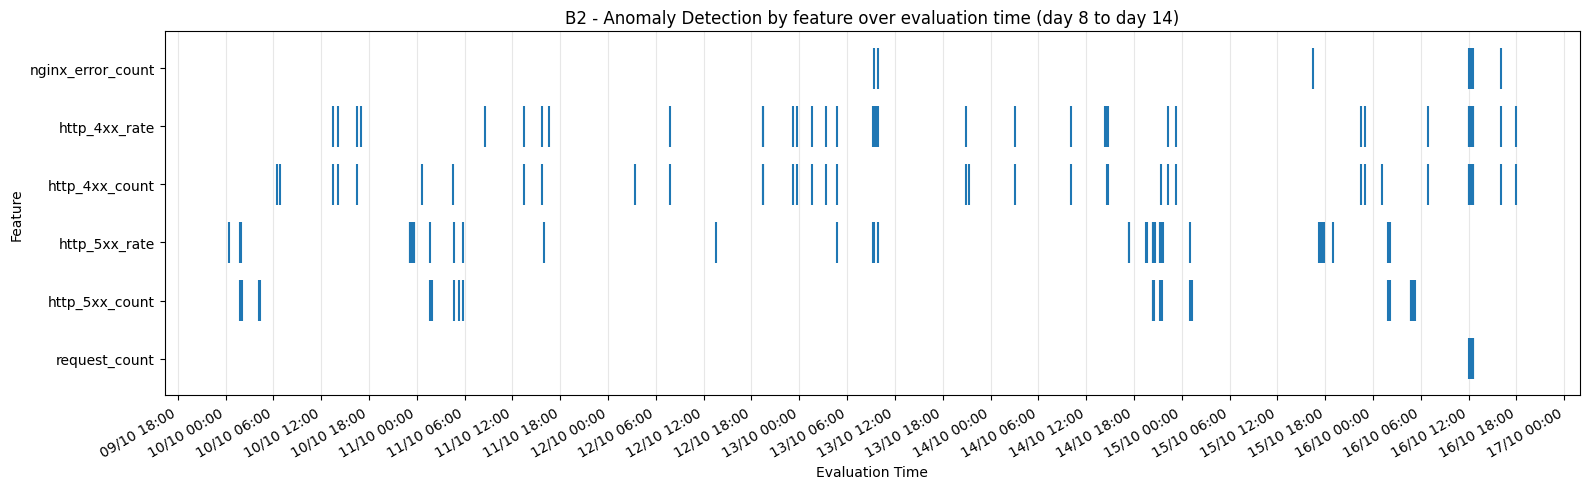

In [106]:
flag_matrix = pd.DataFrame(
    {
        feature: predictions["is_anomaly"].to_numpy()
        for feature, predictions in b2_predictions.items()
    },
    index=pd.to_datetime(b2_evaluation_df["timestamp"]),
)

fig, ax = plt.subplots(figsize=(16, 5))

for y, feature in enumerate(flag_matrix.columns):
    flagged_times = flag_matrix.index[flag_matrix[feature]]
    ax.vlines(flagged_times, y - 0.35, y + 0.35, linewidth=1.5)

ax.set_yticks(range(len(flag_matrix.columns)))
ax.set_yticklabels(flag_matrix.columns)
ax.set_title("B2 - Anomaly Detection by feature over evaluation time (day 8 to day 14)")
ax.set_xlabel("Evaluation Time")
ax.set_ylabel("Feature")

ax.xaxis.set_major_locator(mdates.HourLocator(interval=6))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m %H:%M"))

ax.grid(axis="x", alpha=0.3)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

In [108]:
flagged_by_any_feature = flag_matrix.any(axis=1)
n_flagged_windows = int(flagged_by_any_feature.sum())

print(
    f"Windows flagged by at least one feature: "
    f"{n_flagged_windows} / {len(flag_matrix)} "
    f"({n_flagged_windows / len(flag_matrix):.2%})"
)

Windows flagged by at least one feature: 101 / 2016 (5.01%)


**B2 conclusion**: Compared with B1, the classical Z-score produces a much smaller alert volume. Over 2016 evaluation windows, it flags 7 windows for `request_count` (0.35%), 24 for `http_5xx_count` (1.19%), 42 for `http_5xx_rate` (2.08%), 41 for each of `http_4xx_count` and `http_4xx_rate` (2.03%), and 8 for `nginx_error_count` (0.40%). The absence of labelled incidents means we cannot determine whether these alerts are genuine incidents or false positives. Results also depend on the reference period: unusual values in the first half can affect the mean and standard deviation used to score the second half.

## B3: Robust Z-score (median and MAD)

B3 evaluates the same six indicators as B2 independently, using the same chronological 50/50 reference/evaluation split. It replaces the mean and standard deviation with the reference median and median absolute deviation (MAD). The robust score is `abs(0.6745 * (value - median) / MAD)`; scores strictly greater than 3.5 are flagged. When the reference MAD is zero, values different from the reference median are flagged without generating an infinite score.

In [109]:
b3_features = b2_features.copy()
b3_predictions = {}
b3_summary = []

for feature in b3_features:
    baseline = RobustZScoreBaseline(feature=feature, threshold=3.5)
    baseline.fit(b2_reference_df)
    predictions = baseline.predict(b2_evaluation_df)
    b3_predictions[feature] = predictions
    b3_summary.append(
        {
            "feature": feature,
            "evaluated_windows": len(predictions),
            "flagged_windows": int(predictions["is_anomaly"].sum()),
            "flagged_percentage": predictions["is_anomaly"].mean(),
        }
    )

b3_summary_df = pd.DataFrame(b3_summary)
display(b3_summary_df)

,feature,evaluated_windows,flagged_windows,flagged_percentage
0,request_count,2016,23,0.011409
1,http_5xx_count,2016,113,0.056052
2,http_5xx_rate,2016,309,0.153274
3,http_4xx_count,2016,455,0.225694
4,http_4xx_rate,2016,455,0.225694
5,nginx_error_count,2016,227,0.112599


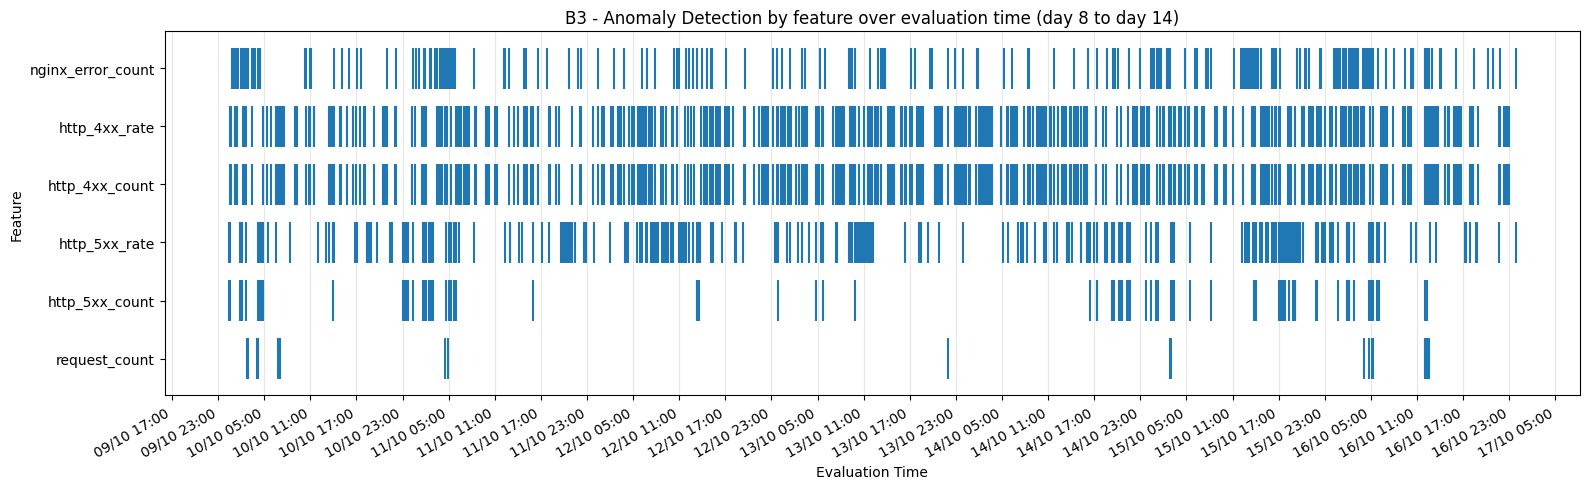

In [110]:
import matplotlib.dates as mdates

b3_flag_matrix = pd.DataFrame(
    {
        feature: predictions["is_anomaly"].to_numpy()
        for feature, predictions in b3_predictions.items()
    },
    index=pd.to_datetime(b2_evaluation_df["timestamp"]),
)

fig, ax = plt.subplots(figsize=(16, 5))
for y, feature in enumerate(b3_flag_matrix.columns):
    flagged_times = b3_flag_matrix.index[b3_flag_matrix[feature]]
    ax.vlines(flagged_times, y - 0.35, y + 0.35, linewidth=1.5)

ax.set_yticks(range(len(b3_flag_matrix.columns)))
ax.set_yticklabels(b3_flag_matrix.columns)
ax.set_title("B3 - Anomaly Detection by feature over evaluation time (day 8 to day 14)")
ax.set_xlabel("Evaluation Time")
ax.set_ylabel("Feature")
ax.xaxis.set_major_locator(mdates.HourLocator(interval=6))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m %H:%M"))
ax.grid(axis="x", alpha=0.3)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

In [113]:
flagged_by_any_feature = b3_flag_matrix.any(axis=1)
n_flagged_windows = int(flagged_by_any_feature.sum())

print(
    f"Windows flagged by at least one feature: "
    f"{n_flagged_windows} / {len(b3_flag_matrix)} "
    f"({n_flagged_windows / len(b3_flag_matrix):.2%})"
)

Windows flagged by at least one feature: 817 / 2016 (40.53%)


In [111]:
b2_b3_comparison_df = b2_summary_df[["feature", "flagged_windows",]].merge(
    b3_summary_df[["feature", "flagged_windows", ]],
    on="feature",
    suffixes=("_b2", "_b3"),
    validate="one_to_one",
)
display(b2_b3_comparison_df)

,feature,flagged_windows_b2,flagged_windows_b3
0,request_count,7,23
1,http_5xx_count,24,113
2,http_5xx_rate,42,309
3,http_4xx_count,41,455
4,http_4xx_rate,41,455
5,nginx_error_count,8,227


In [ ]:
flagged_window_mask = flag_matrix.any(axis=0)
n_flagged_windows = int(flagged_window_mask.sum())

print(f"Unique windows flagged by at least one feature: {n_flagged_windows} / {flag_matrix.shape[1]}")

Unique windows flagged by at least one feature: 101 / 2016
